# 03 — Inventory decisions under uncertainty

Demand and Inventory Planner · Exploratory development analysis · 2026-10-25

**Question:** Does knowing forecast uncertainty improve hypothetical order quantities—and does the boosted model add value over a moving average?

A forecast says how much might sell. A policy chooses how much to order when shortages and leftovers have different costs. Here we compare the four-week moving average and the seven-leaf model from notebook 02, using the same 50 products and ten development origins.

This notebook calibrates **four-week totals**, evaluates forecast ranges and simulates explicit ordering scenarios. The candidate was selected on this same development period, so results are exploratory and subject to selection bias. Final-test forecasts remain unrun. Historical calibration is conditional on the retrospectively training-selected product universe, not a reconstruction of the historical catalog.

**Run:** select `.venv/bin/python`, install `requirements.txt`, run the audit and notebook 02, then run all cells here. The shared helpers are in `scripts/forecasting.py` and `scripts/inventory.py`; model and policy settings were recorded before execution in the [evaluation-plan amendment](../docs/evaluation-plan.md).

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
from pathlib import Path
import hashlib
import json
import platform
import subprocess
import sys
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
import audit as audit_tools
from inventory import (QUANTILES, METHODS, forecast_history, cumulative_forecasts,
                       calibrate_one, simulate_policies, summarize_intervals,
                       summarize_policies, paired_cost_comparisons)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

CONFIG = json.loads((ROOT / 'config.json').read_text())
AUDIT = json.loads((ROOT / 'docs/reports/data-audit.json').read_text())
DEV_START = pd.Timestamp(CONFIG['development_start'])
TEST_START = pd.Timestamp(CONFIG['test_start'])
assert CONFIG['horizon_weeks'] == 4
for name in ['data/processed/weekly-sales.csv', 'data/processed/selected-products.csv', 'data/processed/forecast-origins.csv']:
    assert sha256(ROOT / name) == AUDIT['generated_sha256'][name], name
assert sha256(ROOT / 'config.json') == AUDIT['lineage']['config_sha256']
point_report = json.loads((ROOT / 'docs/reports/forecasting-development.json').read_text())
assert point_report['forecasting_code_sha256'] == sha256(ROOT / 'scripts/forecasting.py'), 'Rerun notebook 02 after changing the shared recipe'
point_path = ROOT / 'data/processed/development-forecast-predictions.csv'
assert sha256(point_path) == point_report['artifacts_sha256'][str(point_path.relative_to(ROOT))]
point_predictions = pd.read_csv(point_path, dtype={'StockCode': str}, parse_dates=['origin', 'target_week'])
point_predictions = point_predictions.loc[point_predictions.method.isin(METHODS)]
panel = pd.read_csv(ROOT / 'data/processed/weekly-sales.csv', dtype={'StockCode': str}, parse_dates=['week'])
panel = panel.loc[panel.week.lt(TEST_START)].copy()
products = pd.read_csv(ROOT / 'data/processed/selected-products.csv', dtype={'StockCode': str})
origins = pd.read_csv(ROOT / 'data/processed/forecast-origins.csv', parse_dates=['origin', 'target_end'])
origins = origins.loc[origins.split.eq('development')]
assert len(products) == 50 and len(origins) == 10 and (origins.target_end < TEST_START).all()
HISTORICAL_ORIGINS = pd.date_range('2010-09-06', origins.origin.max(), freq='W-MON')
EXPERIMENT = {'version': 'inventory-development-v1', 'history_start': '2010-09-06',
              'methods': METHODS, 'product_windows_min': 12, 'history_windows_max': 26,
              'minimum_pool_origins': 4, 'minimum_pool_rows': 12,
              'quantiles': QUANTILES, 'quantile_method': 'linear',
              'shortage_costs': [1, 4, 9], 'surplus_cost': 1,
              'inventory_scenarios': ['zero', 'two_weeks_mean'],
              'bulk_line_cap': 1000, 'bootstrap_block_length': 4,
              'bootstrap_replicates': 500, 'seed': 20261021}
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
print(f'{len(products)} products; {len(origins)} development origins; {len(HISTORICAL_ORIGINS)} replay origins including calibration history')
display(pd.Series(EXPERIMENT, name='fixed scenario settings').to_frame())

50 products; 10 development origins; 49 replay origins including calibration history


,fixed scenario settings
version,inventory-development-v1
history_start,2010-09-06
methods,"[mean_4_weeks, lag_boosting_7]"
product_windows_min,12
history_windows_max,26
minimum_pool_origins,4
minimum_pool_rows,12
quantiles,"{'q025': 0.025, 'q10': 0.1, 'q50': 0.5, 'q80':..."
quantile_method,linear
shortage_costs,"[1, 4, 9]"


## 1. Separate observed sales from stress-test assumptions

The primary variant preserves the audit's positive recorded sales. Two separately labeled sensitivities freeze the product universe and calendar grid:

- **Drop exact repeats:** remove repeated invoice lines after sheet reconciliation; no line-item key proves that these repeats are erroneous.
- **Cap 1,000 units per line:** truncate unusually large positive invoice-line quantities at a fixed threshold. This is a **counterfactual sensitivity**, not a claim that those bulk purchases are mistakes.

Each sensitivity consistently changes training targets, historical residuals and evaluation actuals. Compare methods **within** each sales definition; absolute costs across variants have different denominators. The large-order examples below are real source rows from before the final partition.

In [2]:
raw, _ = audit_tools.load_source(ROOT)
clean, _ = audit_tools.reconcile_sheets(raw)
lines = clean.loc[audit_tools.sales_mask(clean, CONFIG) & clean.timestamp.lt(TEST_START)].copy()
lines['week'] = lines.timestamp.dt.to_period('W-SUN').dt.start_time
lines = lines.loc[lines.week.isin(panel.week.unique()) & lines.StockCode.isin(products.StockCode)].copy()
print('Largest uncapped selected-product invoice lines before final evaluation:')
display(lines.nlargest(10, 'Quantity')[['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Country']])
grid = panel.set_index(['StockCode', 'week'])
variant_panels, sensitivity_rows = {}, []
for variant in ['original', 'drop_exact_repeats', 'cap_1000_units']:
    changed = lines.copy()
    affected_rows, units_changed = 0, 0
    if variant == 'drop_exact_repeats':
        repeated = changed.duplicated(audit_tools.COLUMNS)
        affected_rows, units_changed = int(repeated.sum()), int(changed.loc[repeated, 'Quantity'].sum())
        changed = changed.loc[~repeated]
    elif variant == 'cap_1000_units':
        affected_rows = int(changed.Quantity.gt(EXPERIMENT['bulk_line_cap']).sum())
        before = changed.Quantity.sum()
        changed['Quantity'] = changed.Quantity.clip(upper=EXPERIMENT['bulk_line_cap'])
        units_changed = int(before - changed.Quantity.sum())
    weekly = changed.groupby(['StockCode', 'week']).Quantity.sum().reindex(grid.index, fill_value=0)
    variant_panel = grid.copy()
    variant_panel['units'] = weekly
    variant_panels[variant] = variant_panel.reset_index()
    sensitivity_rows.append({'variant': variant, 'source_lines_affected': affected_rows,
                             'recorded_units_removed_or_capped': units_changed,
                             'remaining_recorded_units_before_test': int(weekly.sum())})
np.testing.assert_array_equal(variant_panels['original'].units, panel.units)
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)
del raw, clean, lines, changed
print('PASS: rebuilt primary weekly targets exactly match the audited panel.')

Largest uncapped selected-product invoice lines before final evaluation:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,United Kingdom
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,United Kingdom
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,United Kingdom
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,2010-03-23 15:36:00,0.25,United Kingdom
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,United Kingdom
326847,521315,17003,BROCADE RING PURSE,7128,2010-09-03 12:01:00,0.19,United Kingdom
432177,530715,17003,BROCADE RING PURSE,6336,2010-11-04 11:36:00,0.19,United Kingdom
201392,508748,21985,PACK OF 12 HEARTS DESIGN TISSUES,5000,2010-05-18 11:45:00,0.50,United Kingdom
201394,508748,21982,PACK OF 12 SUKI TISSUES,5000,2010-05-18 11:45:00,0.50,United Kingdom
379876,525968,17003,BROCADE RING PURSE,4752,2010-10-08 10:10:00,0.19,United Kingdom


,variant,source_lines_affected,recorded_units_removed_or_capped,remaining_recorded_units_before_test
0,original,0,0,1547896
1,drop_exact_repeats,682,5136,1542760
2,cap_1000_units,98,127860,1420036


PASS: rebuilt primary weekly targets exactly match the audited panel.


## 2. Recreate forecasts before learning their errors

At every replay origin, fit on completed prior targets and forecast four future weeks. A product needs 26 weeks of prior observations to enter replay. Every origin has a new fitted pooled model; the moving average uses each product's preceding four weeks.

For each historical forecast we save its predicted total, eventual recorded total, signed error, and the Sunday when that entire outcome became available. Original development point forecasts must reproduce notebook 02 before we proceed.

In [3]:
weekly_runs, cumulative_runs = [], []
started = time.perf_counter()
for variant, variant_panel in variant_panels.items():
    weekly = forecast_history(variant_panel, HISTORICAL_ORIGINS, variant)
    assert weekly.target_week.max() < TEST_START
    assert (weekly.fit_max_target_week < weekly.origin).all()
    weekly_runs.append(weekly)
    cumulative_runs.append(cumulative_forecasts(weekly))
    print(f'{variant}: {weekly.origin.nunique()} origins; {len(weekly):,} weekly forecast rows', flush=True)
weekly_forecasts = pd.concat(weekly_runs, ignore_index=True)
cumulative = pd.concat(cumulative_runs, ignore_index=True)
replayed = weekly_forecasts.loc[weekly_forecasts.variant.eq('original') & weekly_forecasts.origin.isin(origins.origin)]
keys = ['method', 'StockCode', 'origin', 'horizon', 'target_week']
expected = point_predictions.sort_values(keys).reset_index(drop=True)
observed = replayed.sort_values(keys).reset_index(drop=True)
pd.testing.assert_frame_equal(expected[keys + ['actual', 'prediction']], observed[keys + ['actual', 'prediction']], check_dtype=False, check_exact=False, rtol=1e-9, atol=1e-9)
assert not cumulative.forecast_id.duplicated().any()
print(f'PASS: original development predictions reproduce notebook 02. Replay runtime: {time.perf_counter() - started:.1f}s.')

original: 49 origins; 19,408 weekly forecast rows


drop_exact_repeats: 49 origins; 19,408 weekly forecast rows


cap_1000_units: 49 origins; 19,408 weekly forecast rows


PASS: original development predictions reproduce notebook 02. Replay runtime: 18.6s.


## 3. Learn ranges only from completed forecast windows

For a Monday order, take historical **four-week-total errors** whose windows ended before that Monday. Prefer the product's most recent 26 completed windows when at least 12 exist. Otherwise pool scale-normalized errors from other selected products of the same method, disclosing that fallback. Normalization uses only pre-origin sales means.

Add empirical error quantiles to the current point total. The 10th–90th percentiles form an 80% range; 2.5th–97.5th form a 95% range. Negative endpoints are clipped to zero. These are empirical predictive ranges under temporal dependence, not guaranteed coverage or confidence intervals for a mean.

The timeline and saved membership make it possible to verify exactly which outcomes informed each order. Overlapping windows are allowed only once fully observed; they do not count as independent evidence.

,variant,method,product_origins,cumulative_MAE,coverage80,coverage95,width80,width95,pooled_fallback_rows,minimum_calibration_rows,maximum_calibration_rows,pinball_q10,pinball_q50,pinball_q90
0,cap_1000_units,lag_boosting_7,500,434.288,0.810,0.896,1316.041,1774.339,0,26,26,81.228,211.542,132.656
1,cap_1000_units,mean_4_weeks,500,459.628,0.800,0.878,1526.641,1933.598,0,26,26,106.892,245.726,139.751
2,drop_exact_repeats,lag_boosting_7,500,489.729,0.788,0.888,1428.877,1912.938,0,26,26,92.684,236.693,160.175
3,drop_exact_repeats,mean_4_weeks,500,524.926,0.804,0.878,1677.612,2126.402,0,26,26,125.062,276.366,163.314
4,original,lag_boosting_7,500,501.435,0.798,0.884,1448.225,1932.732,0,26,26,93.788,242.721,170.425
5,original,mean_4_weeks,500,542.668,0.802,0.878,1679.539,2131.649,0,26,26,131.528,285.406,174.664


Calibration membership links: 78000
PASS: no unfinished outcome enters calibration; future/current actual changes do not change its quantiles.


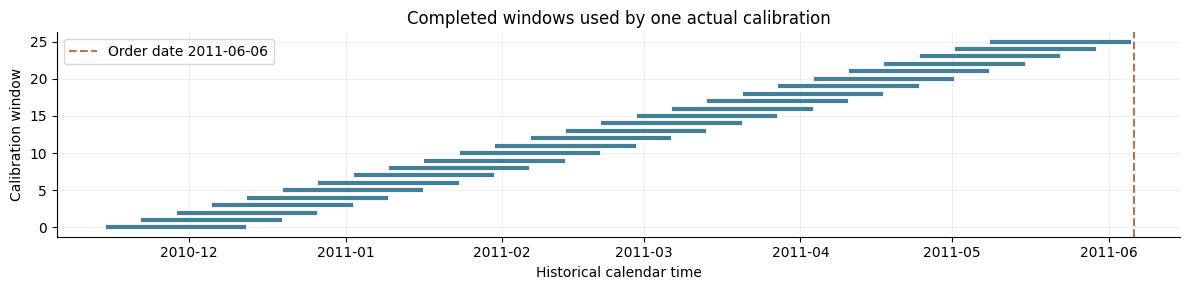

In [4]:
development = cumulative.loc[cumulative.origin.isin(origins.origin)].copy()
assert development.groupby(['variant', 'method']).size().eq(500).all()
quantile_rows, membership_rows = [], []
for row in development.itertuples(index=False):
    estimate, members = calibrate_one(row, cumulative)
    quantile_rows.append({'forecast_id': row.forecast_id, **estimate})
    membership_rows.append(members)
calibrated = development.merge(pd.DataFrame(quantile_rows), on='forecast_id', validate='one_to_one')
membership = pd.concat(membership_rows, ignore_index=True)
assert (calibrated.calibration_latest_target_end < calibrated.origin).all()
assert np.isfinite(calibrated[list(QUANTILES)]).all().all()
assert (np.diff(calibrated[list(QUANTILES)].to_numpy(), axis=1) >= 0).all()
assert calibrated[list(QUANTILES)].ge(0).all().all()
# Adding extreme future residuals or changing the current actual must not change the issued range.
check_row = development.iloc[0].copy()
reference, _ = calibrate_one(check_row, cumulative)
changed = cumulative.copy()
changed.loc[changed.target_end.ge(check_row.origin), 'residual'] = 1e12
check_row['actual'] = 1e12
unchanged, _ = calibrate_one(check_row, changed)
assert reference == unchanged
interval_metrics = summarize_intervals(calibrated)
display(interval_metrics.round(3))
print('Calibration membership links:', len(membership))
print('PASS: no unfinished outcome enters calibration; future/current actual changes do not change its quantiles.')

example = calibrated.loc[calibrated.variant.eq('original') & calibrated.method.eq('mean_4_weeks')].iloc[0]
used = membership.loc[membership.forecast_id.eq(example.forecast_id)].sort_values('calibration_origin')
fig, ax = plt.subplots(figsize=(12, 3))
for i, row in enumerate(used.itertuples()):
    ax.plot([row.calibration_origin, row.calibration_target_end], [i, i], color='#437f97', linewidth=3)
ax.axvline(example.origin, color='#b07650', linestyle='--', label=f'Order date {example.origin.date()}')
ax.set(title='Completed windows used by one actual calibration', xlabel='Historical calendar time', ylabel='Calibration window')
ax.legend()
fig.tight_layout()
plt.show()

## 4. Check coverage, sharpness and failure cases

A useful range should cover enough outcomes without being unnecessarily wide. Report both coverage and width. Pinball loss measures quantile error; lower is better. Coverage is a rate across 500 overlapping product-origins per method, not 500 independent trials.

The examples below use the leading product by initial training volume and both methods. The displayed bands concern a whole four-week sum; neighboring points represent overlapping windows, not consecutive inventory cycles.

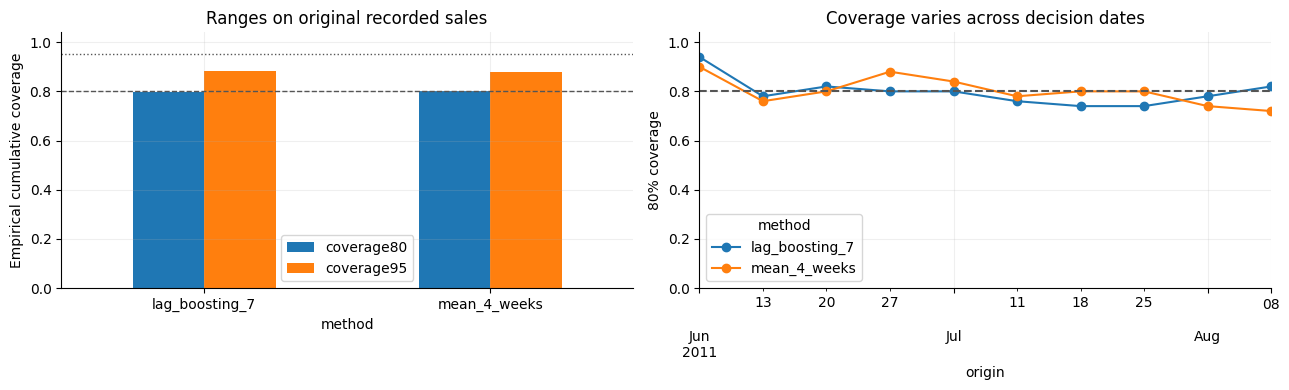

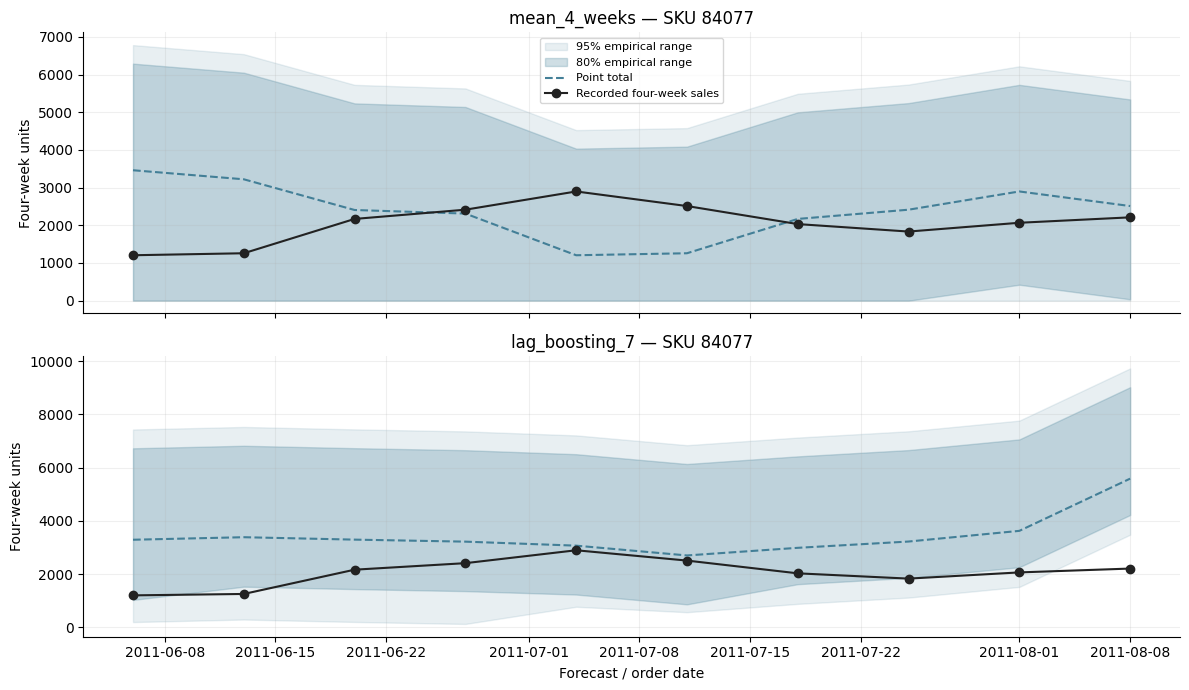

,method,StockCode,origin,actual,prediction,q10,q90,distance_outside80
384,lag_boosting_7,84568,2011-07-04,5019.0,574.759241,0.000000,684.007033,4334.992967
385,lag_boosting_7,84568,2011-07-11,5063.0,633.039033,0.000000,742.286826,4320.713174
918,mean_4_weeks,84879,2011-08-01,6473.0,1717.000000,912.000000,2401.500000,4071.500000
916,mean_4_weeks,84879,2011-07-18,6018.0,1344.000000,324.000000,1960.000000,4058.000000
917,mean_4_weeks,84879,2011-07-25,6063.0,1593.000000,788.000000,2209.000000,3854.000000
885,mean_4_weeks,84568,2011-07-11,5063.0,349.000000,0.000000,1300.000000,3763.000000
386,lag_boosting_7,84568,2011-07-18,4515.0,860.355967,0.000000,1051.396829,3463.603171
884,mean_4_weeks,84568,2011-07-04,5019.0,629.000000,0.000000,1580.000000,3439.000000
888,mean_4_weeks,84568,2011-08-01,87.0,5019.000000,3521.000000,6229.000000,3434.000000
416,lag_boosting_7,84879,2011-07-18,6018.0,2235.675302,890.413828,2618.011761,3399.988239


In [5]:
original = calibrated.loc[calibrated.variant.eq('original')].copy()
original['covered80'] = original.actual.between(original.q10, original.q90)
coverage_by_origin = original.groupby(['method', 'origin']).covered80.mean().unstack('method')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
interval_metrics.loc[interval_metrics.variant.eq('original')].set_index('method')[['coverage80', 'coverage95']].plot.bar(ax=axes[0], rot=0)
axes[0].axhline(.8, color='#555555', linestyle='--', linewidth=1)
axes[0].axhline(.95, color='#555555', linestyle=':', linewidth=1)
axes[0].set(ylim=(0, 1.04), ylabel='Empirical cumulative coverage', title='Ranges on original recorded sales')
coverage_by_origin.plot(ax=axes[1], marker='o')
axes[1].axhline(.8, color='#555555', linestyle='--')
axes[1].set(ylim=(0, 1.04), ylabel='80% coverage', title='Coverage varies across decision dates')
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
example_sku = str(products.StockCode.iloc[0])
for ax, method in zip(axes, METHODS):
    view = original.loc[original.StockCode.eq(example_sku) & original.method.eq(method)].sort_values('origin')
    ax.fill_between(view.origin, view.q025, view.q975, alpha=.12, color='#437f97', label='95% empirical range')
    ax.fill_between(view.origin, view.q10, view.q90, alpha=.25, color='#437f97', label='80% empirical range')
    ax.plot(view.origin, view.prediction, '--', color='#437f97', label='Point total')
    ax.plot(view.origin, view.actual, 'o-', color='#222222', label='Recorded four-week sales')
    ax.set(title=f'{method} — SKU {example_sku}', ylabel='Four-week units')
axes[0].legend(fontsize=8)
axes[-1].set_xlabel('Forecast / order date')
fig.tight_layout()
plt.show()
failures = original.assign(miss_below=np.maximum(original.q10 - original.actual, 0),
                           miss_above=np.maximum(original.actual - original.q90, 0))
failures['distance_outside80'] = failures.miss_below + failures.miss_above
display(failures.sort_values('distance_outside80', ascending=False)[['method', 'StockCode', 'origin', 'actual', 'prediction', 'q10', 'q90', 'distance_outside80']].head(10))

## 5. Turn forecasts into explicit hypothetical orders

For shortage penalty `Cu` and surplus penalty `Co`, use the sales quantile at `Cu / (Cu + Co)`. With Cu=4 and Co=1, this is the 80th percentile. Compare that policy with ordering the point forecast.

`order = max(0, ceil(target − inventory_position))`

`cost = Cu × shortage_units + Co × surplus_units`

We test Cu/Co ratios 1, 4 and 9, with either zero starting stock or the ceiling of two recent-average weeks. Every decision is an independent four-week protection window. The hypothetical order is assumed available before the window begins, with no additional receipts during it. This does **not** model a real supplier lead-time, shipping delay, ongoing stock trajectory, purchasing budget or procurement bill. Costs are arbitrary scenario units; quantities are based on recorded sales rather than recovered lost demand.

,method,policy,product_origins,mean_cost,shortage_units,surplus_units,mean_order_units,simulated_unit_fulfillment,actual_units_denominator
51,lag_boosting_7,point,500,1117.582,102670.0,148111.0,1236.534,0.821,572826.0
57,lag_boosting_7,quantile,500,1093.990,65669.0,284319.0,1582.952,0.885,572826.0
63,mean_4_weeks,point,500,1381.078,139735.0,131599.0,1129.380,0.756,572826.0
69,mean_4_weeks,quantile,500,1230.776,62085.0,367048.0,1755.578,0.892,572826.0


Worked decision for SKU 84077 at 2011-06-06:


,method,policy,actual,target,initial_inventory,order,shortage,surplus,cost
12340,lag_boosting_7,point,1205.0,3292.87,0.0,3293.0,0.0,2088.0,2088.0
12840,mean_4_weeks,point,1205.0,3461.00,0.0,3461.0,0.0,2256.0,2256.0
15340,lag_boosting_7,quantile,1205.0,5033.56,0.0,5034.0,0.0,3829.0,3829.0
15840,mean_4_weeks,quantile,1205.0,5909.00,0.0,5909.0,0.0,4704.0,4704.0


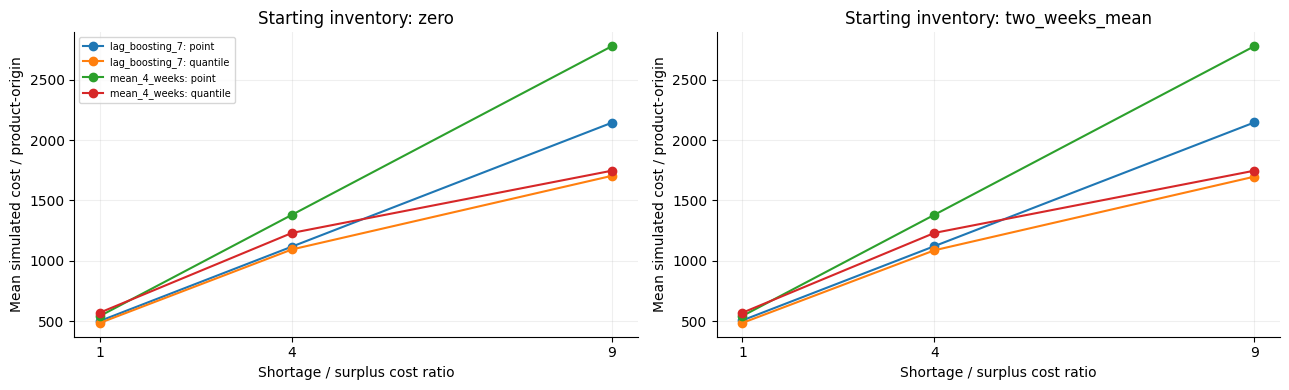

In [6]:
policies = simulate_policies(calibrated)
policy_metrics = summarize_policies(policies)
assert policies.groupby(['variant', 'method', 'policy', 'Cu', 'inventory_scenario']).size().eq(500).all()
assert policies.order.ge(0).all() and policies.order.mod(1).eq(0).all()
assert np.allclose(policies.cost, policies.Cu * policies.shortage + policies.Co * policies.surplus)
primary = policy_metrics.loc[policy_metrics.variant.eq('original') & policy_metrics.Cu.eq(4) & policy_metrics.inventory_scenario.eq('zero')]
display(primary[['method', 'policy', 'product_origins', 'mean_cost', 'shortage_units', 'surplus_units', 'mean_order_units', 'simulated_unit_fulfillment', 'actual_units_denominator']].round(3))
# Follow the exact same source product/date through all four ordering choices.
worked = policies.loc[policies.variant.eq('original') & policies.Cu.eq(4)
                      & policies.inventory_scenario.eq('zero') & policies.StockCode.eq(example_sku)
                      & policies.origin.eq(origins.origin.min())]
print(f'Worked decision for SKU {example_sku} at {origins.origin.min().date()}:')
display(worked[['method', 'policy', 'actual', 'target', 'initial_inventory', 'order', 'shortage', 'surplus', 'cost']].round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, inventory_name in zip(axes, ['zero', 'two_weeks_mean']):
    view = policy_metrics.loc[policy_metrics.variant.eq('original') & policy_metrics.inventory_scenario.eq(inventory_name)]
    for (method, policy), group in view.groupby(['method', 'policy']):
        ax.plot(group.Cu, group.mean_cost, marker='o', label=f'{method}: {policy}')
    ax.set(title=f'Starting inventory: {inventory_name}', xlabel='Shortage / surplus cost ratio', ylabel='Mean simulated cost / product-origin', xticks=[1, 4, 9])
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 6. Paired comparisons and robustness

Compare the exact same product-origin decisions. Negative cost difference favors the candidate. Block resampling uses four consecutive origins, carries all products together, and repeats 500 times. With only ten overlapping origins these intervals are descriptive sensitivity estimates, not strong evidence of reliable savings.

The duplicate and quantity-cap variants are fully replayed and recalibrated. A ranking that reverses under an alternative data assumption deserves investigation. We do not treat the counterfactual cap as a preferred cleaned dataset.

,variant,candidate,comparator,mean_cost_difference,bootstrap_low,bootstrap_high,cost_reduction_pct,origins,product_origins
12,cap_1000_units,mean_4_weeks/quantile,mean_4_weeks/point,-150.134,-349.555,27.666,12.743,10,500
13,cap_1000_units,lag_boosting_7/quantile,lag_boosting_7/point,-58.722,-212.679,76.264,6.140,10,500
14,cap_1000_units,lag_boosting_7/quantile,mean_4_weeks/quantile,-130.398,-141.779,-86.972,12.684,10,500
15,cap_1000_units,lag_boosting_7/point,mean_4_weeks/point,-221.810,-259.932,-169.980,18.827,10,500
36,drop_exact_repeats,mean_4_weeks/quantile,mean_4_weeks/point,-159.808,-418.826,78.720,12.042,10,500
37,drop_exact_repeats,lag_boosting_7/quantile,lag_boosting_7/point,-16.022,-137.606,89.362,1.498,10,500
38,drop_exact_repeats,lag_boosting_7/quantile,mean_4_weeks/quantile,-113.980,-176.866,13.220,9.765,10,500
39,drop_exact_repeats,lag_boosting_7/point,mean_4_weeks/point,-257.766,-315.226,-170.970,19.424,10,500
60,original,mean_4_weeks/quantile,mean_4_weeks/point,-150.302,-410.202,89.548,10.883,10,500
61,original,lag_boosting_7/quantile,lag_boosting_7/point,-23.592,-154.766,98.526,2.111,10,500


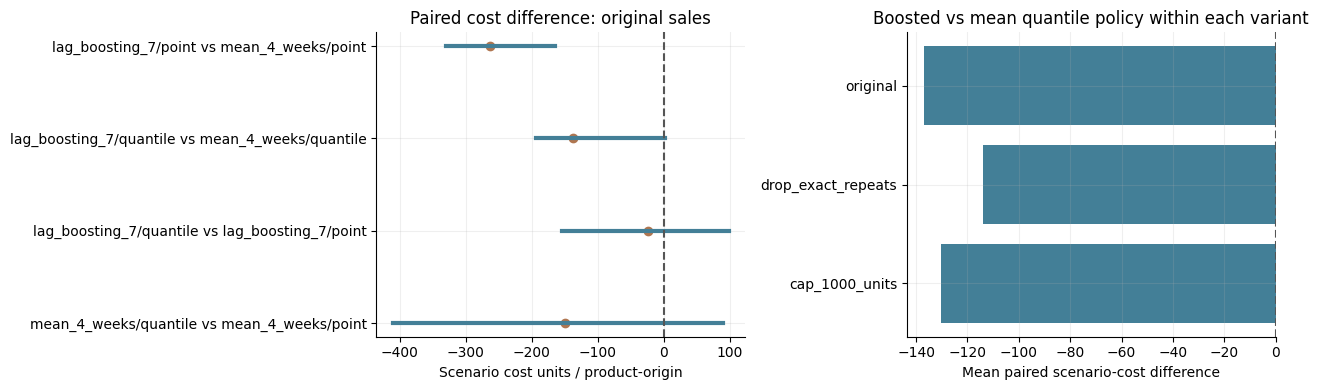

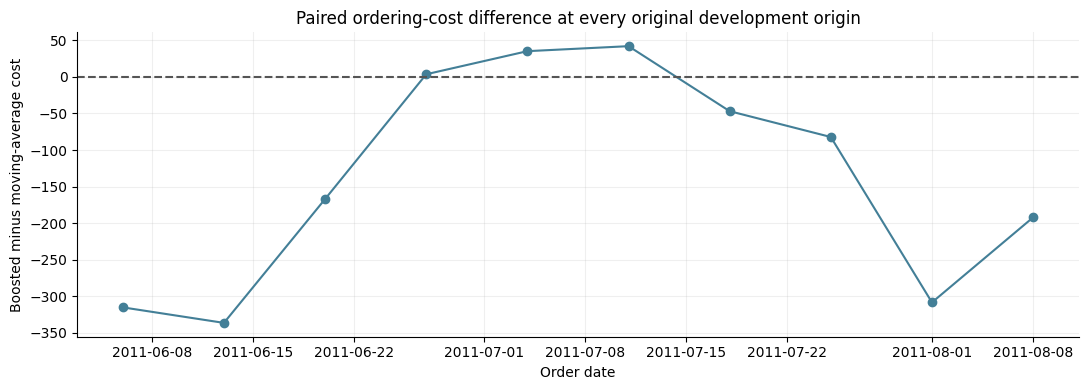

,variant,method,coverage80,coverage95,width80,pinball_q10,pinball_q50,pinball_q90
0,cap_1000_units,lag_boosting_7,0.810,0.896,1316.041,81.228,211.542,132.656
1,cap_1000_units,mean_4_weeks,0.800,0.878,1526.641,106.892,245.726,139.751
2,drop_exact_repeats,lag_boosting_7,0.788,0.888,1428.877,92.684,236.693,160.175
3,drop_exact_repeats,mean_4_weeks,0.804,0.878,1677.612,125.062,276.366,163.314
4,original,lag_boosting_7,0.798,0.884,1448.225,93.788,242.721,170.425
5,original,mean_4_weeks,0.802,0.878,1679.539,131.528,285.406,174.664


In [7]:
comparisons, origin_differences = paired_cost_comparisons(policies)
primary_comparisons = comparisons.loc[comparisons.Cu.eq(4) & comparisons.inventory_scenario.eq('zero')]
display(primary_comparisons[['variant', 'candidate', 'comparator', 'mean_cost_difference', 'bootstrap_low', 'bootstrap_high', 'cost_reduction_pct', 'origins', 'product_origins']].round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
view = primary_comparisons.loc[primary_comparisons.variant.eq('original')].reset_index(drop=True)
for i, row in view.iterrows():
    axes[0].plot([row.bootstrap_low, row.bootstrap_high], [i, i], linewidth=3, color='#437f97')
    axes[0].scatter(row.mean_cost_difference, i, color='#b07650')
axes[0].axvline(0, color='#555555', linestyle='--')
axes[0].set(yticks=range(len(view)), yticklabels=[f'{r.candidate} vs {r.comparator}' for r in view.itertuples()],
            title='Paired cost difference: original sales', xlabel='Scenario cost units / product-origin')
robust = primary_comparisons.loc[primary_comparisons.candidate.eq('lag_boosting_7/quantile') & primary_comparisons.comparator.eq('mean_4_weeks/quantile')]
axes[1].barh(robust.variant, robust.mean_cost_difference, color='#437f97')
axes[1].axvline(0, color='#555555', linestyle='--')
axes[1].set(title='Boosted vs mean quantile policy within each variant', xlabel='Mean paired scenario-cost difference', ylabel='')
fig.tight_layout()
plt.show()
view = origin_differences.loc[origin_differences.variant.eq('original') & origin_differences.Cu.eq(4)
                              & origin_differences.inventory_scenario.eq('zero')
                              & origin_differences.candidate.eq('lag_boosting_7/quantile')
                              & origin_differences.comparator.eq('mean_4_weeks/quantile')]
fig, ax = plt.subplots()
ax.plot(view.origin, view.mean_cost_difference, 'o-', color='#437f97')
ax.axhline(0, color='#555555', linestyle='--')
ax.set(title='Paired ordering-cost difference at every original development origin', xlabel='Order date', ylabel='Boosted minus moving-average cost')
fig.tight_layout()
plt.show()
display(interval_metrics[['variant', 'method', 'coverage80', 'coverage95', 'width80', 'pinball_q10', 'pinball_q50', 'pinball_q90']].round(3))

### What the first run shows

- **80% ranges are close to their target:** 80.2% coverage for the moving average and 79.8% for boosting. **95% ranges under-cover:** only 87.8% and 88.4%. Tail uncertainty needs further work; narrow ranges alone are not success.
- At shortage/surplus costs 4:1 with zero initial stock, ordering the cost-based quantile reduces mean simulated cost versus ordering the point total by about **10.9% for the mean** and **2.1% for boosting**. Both paired block intervals cross zero.
- Boosted quantile ordering averages **11.1% lower scenario cost than mean quantile ordering**, but its cost-difference interval is approximately **[-193.22, +2.17]** units per decision. That does not establish a reliable advantage.
- The boosted quantile policy's average ranking persists after duplicate removal and the fixed bulk-order cap. The cap changes the target and is not evidence that large original sales were invalid.

These are the recorded first run's development findings. Do not promote a model, claim real savings, or describe the empirical 95% ranges as well calibrated. Next investigate tail calibration and origin/product failures, document any amendment, and freeze the recipe before final evaluation.

## 7. Save the evidence and decide what remains unresolved

Save weekly/cumulative forecasts, exact calibration membership and every scenario order for reproducible review. Compact summaries and lineage are committed; large replay artifacts stay in the regenerable processed-data directory. The conclusion below is generated from the actual run. No model promotion or measured company benefit follows from these exploratory scenarios.

In [8]:
REPORTS, PROCESSED = ROOT / 'docs/reports', ROOT / 'data/processed'
outputs = {PROCESSED / 'inventory-historical-weekly.csv': weekly_forecasts,
           PROCESSED / 'inventory-historical-cumulative.csv': cumulative,
           PROCESSED / 'inventory-development-calibrated.csv': calibrated,
           PROCESSED / 'inventory-calibration-membership.csv': membership,
           PROCESSED / 'inventory-scenario-orders.csv': policies,
           PROCESSED / 'inventory-failure-cases.csv': failures.sort_values('distance_outside80', ascending=False).head(20),
           REPORTS / 'inventory-interval-metrics.csv': interval_metrics,
           REPORTS / 'inventory-policy-metrics.csv': policy_metrics,
           REPORTS / 'inventory-paired-comparisons.csv': comparisons,
           REPORTS / 'inventory-origin-cost-differences.csv': origin_differences,
           REPORTS / 'inventory-data-sensitivity.csv': sensitivity}
for path, frame in outputs.items():
    frame.to_csv(path, index=False)
nb_path = ROOT / 'notebooks/03-inventory-decisions.ipynb'
notebook_on_disk = json.loads(nb_path.read_text())
source_text = json.dumps([{'cell_type': c['cell_type'], 'source': ''.join(c['source'])} for c in notebook_on_disk['cells']], sort_keys=True)
original_intervals = interval_metrics.loc[interval_metrics.variant.eq('original')].set_index('method')
primary_comparison = primary_comparisons.loc[primary_comparisons.variant.eq('original')
                                            & primary_comparisons.candidate.eq('lag_boosting_7/quantile')
                                            & primary_comparisons.comparator.eq('mean_4_weeks/quantile')].iloc[0]
report = {'experiment': EXPERIMENT, 'date': '2026-10-25',
          'population': '50 original training-selected UK products; ten development origins; no final forecast evaluation',
          'notebook_source_sha256': hashlib.sha256(source_text.encode()).hexdigest(),
          'code_sha256': {name: sha256(ROOT / name) for name in ['scripts/forecasting.py', 'scripts/inventory.py', 'scripts/audit.py', 'tests/test_inventory.py']},
          'config_sha256': sha256(ROOT / 'config.json'),
          'audit_report_sha256': sha256(ROOT / 'docs/reports/data-audit.json'),
          'panel_sha256': sha256(ROOT / 'data/processed/weekly-sales.csv'),
          'point_report_sha256': sha256(ROOT / 'docs/reports/forecasting-development.json'),
          'origins_sha256': sha256(ROOT / 'data/processed/forecast-origins.csv'),
          'products_sha256': sha256(ROOT / 'data/processed/selected-products.csv'),
          'source_csv_sha256': AUDIT['lineage']['sources'], 'python': platform.python_version(),
          'packages': {name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'scipy', 'joblib', 'threadpoolctl']},
          'git_revision': subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True, capture_output=True, check=True).stdout.strip(),
          'git_worktree_dirty': bool(subprocess.run(['git', 'status', '--porcelain'], cwd=ROOT, text=True, capture_output=True, check=True).stdout.strip()),
          'artifact_sha256': {str(path.relative_to(ROOT)): sha256(path) for path in outputs},
          'interval_metrics': json.loads(interval_metrics.to_json(orient='records')),
          'primary_comparisons': json.loads(primary_comparisons.to_json(orient='records')),
          'checks': ['original panel reconstruction', 'notebook 02 point prediction consistency',
                     'all fitting targets pre-origin', 'only completed calibration windows',
                     'future/current outcome calibration invariance', 'finite nonnegative monotone quantiles',
                     'identical 500-product-origin policy populations', 'integer nonnegative orders', 'scenario cost identity'],
          'limitations': ['Post-selection development analysis', 'Recorded sales, unknown unconstrained demand',
                         'Retrospectively fixed product universe for historical calibration', 'Ten overlapping origins',
                         'Empirical ranges without formal coverage guarantees', 'Hypothetical window costs and immediate order availability',
                         'Counterfactual bulk-order cap is a sensitivity only', 'No final evaluation, promotion or production deployment']}
(REPORTS / 'inventory-development.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n')
summary = f"""# Inventory decisions under uncertainty

Executed 2026-10-25 via `notebooks/03-inventory-decisions.ipynb`. Two methods, 50 fixed UK products, ten development origins and three sales definitions. The seven-leaf model was selected on this same development period; all results remain exploratory. No final-test forecast evaluation or production promotion has run.

Original-sales 80% cumulative coverage: moving average {original_intervals.loc['mean_4_weeks', 'coverage80']:.1%}; boosted model {original_intervals.loc['lag_boosting_7', 'coverage80']:.1%}. The corresponding 95% coverage rates are {original_intervals.loc['mean_4_weeks', 'coverage95']:.1%} and {original_intervals.loc['lag_boosting_7', 'coverage95']:.1%}. Both nominal 95% ranges substantially under-cover; tail calibration needs further work. See interval metrics for widths, quantile losses, denominators and fallback counts. Every residual window ended before its new order date; exact membership is saved.

For the primary Cu=4, Co=1, zero-inventory scenario, boosted-quantile minus moving-average-quantile mean cost is {primary_comparison.mean_cost_difference:.2f} arbitrary cost units per product-origin. The paired four-origin-block bootstrap interval is [{primary_comparison.bootstrap_low:.2f}, {primary_comparison.bootstrap_high:.2f}], from 500 replicates over just ten overlapping origins. Negative favors boosting. This is simulated policy value against recorded sales, not realized savings or strong evidence of a dependable advantage.

All six cost/inventory scenarios and point-versus-quantile comparisons are saved. Both methods were refitted/recalibrated after exact-repeat removal and under a labeled counterfactual 1,000-unit invoice-line cap. Those variants change the sales target; compare rankings within each, not absolute profits between variants. Large uncapped orders and original interval failure cases appear in the notebook.

Next: review coverage and robustness failures, decide whether to amend the recipe, freeze it before final evaluation, and complete promotion gates. The scenario assumes orders available at the start of an independent four-week protection window; it does not model a supplier delay or ongoing inventory. No actual inventory/cost records, deployment, registry, monitoring or rollback evidence are supplied by this notebook.
"""
(REPORTS / '03-inventory-decisions.md').write_text(summary)
print(summary)
print(f'Saved {len(outputs)} hashed artifacts, including {len(policies):,} scenario orders and {len(membership):,} calibration links.')

# Inventory decisions under uncertainty

Executed 2026-10-25 via `notebooks/03-inventory-decisions.ipynb`. Two methods, 50 fixed UK products, ten development origins and three sales definitions. The seven-leaf model was selected on this same development period; all results remain exploratory. No final-test forecast evaluation or production promotion has run.

Original-sales 80% cumulative coverage: moving average 80.2%; boosted model 79.8%. The corresponding 95% coverage rates are 87.8% and 88.4%. Both nominal 95% ranges substantially under-cover; tail calibration needs further work. See interval metrics for widths, quantile losses, denominators and fallback counts. Every residual window ended before its new order date; exact membership is saved.

For the primary Cu=4, Co=1, zero-inventory scenario, boosted-quantile minus moving-average-quantile mean cost is -136.79 arbitrary cost units per product-origin. The paired four-origin-block bootstrap interval is [-193.22, 2.17], from 500 rep

## Before moving toward an application

Use the observed coverage, point-versus-quantile costs, origin-level variability and data-sensitivity rankings to assess the recipe. A model that predicts average sales well may still yield poor tail decisions. Conversely, better simulated costs under one assumed ratio may disappear when costs or data definitions change.

If calibration is inadequate, document the change and repeat development analysis rather than tuning on final outcomes. Freeze a defensible recipe before final evaluation. A real replenishment rollout additionally needs inventory positions, supplier timing, on-order receipts and operational cost/availability evidence.